# Library and Project Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset

In [3]:
df = pd.read_csv("../data/raw/student_dropout.csv")

# Initial Inspection of the Datset

In [4]:
#Show the first five rows of the data
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [5]:
#Show the dimensions (rows and columns) of the data
print("Dataset Shape: ", df.shape)

Dataset Shape:  (4424, 35)


In [6]:
#Show the column names within the data
print("\nDataset Columns: ")
print(df.columns.tolist())


Dataset Columns: 
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


# Missing values

In [7]:
#Checking the dataset for missing values
missing_values = df.isnull().sum().sort_values(ascending=False)

#Print the total of missing values
print("Total missing values: ", missing_values.sum())

Total missing values:  0


# Duplicate Rows

In [8]:
#Checking the dataset for duplicate rows
duplicates = df.duplicated().sum()

#Print the total of duplicate rows
print("Total duplicate rows: ", duplicates.sum())

Total duplicate rows:  0


# Target distribution (multi-class classification)

In [9]:
#Count the records in each of the target classes
target_counts = df["Target"].value_counts()

#Calculate class percentages
target_percentages = df["Target"].value_counts(normalize=True) * 100

#Combine into a dataframe to visualise the results
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

print(target_summary)


          Count  Percentage
Target                     
Graduate   2209       49.93
Dropout    1421       32.12
Enrolled    794       17.95


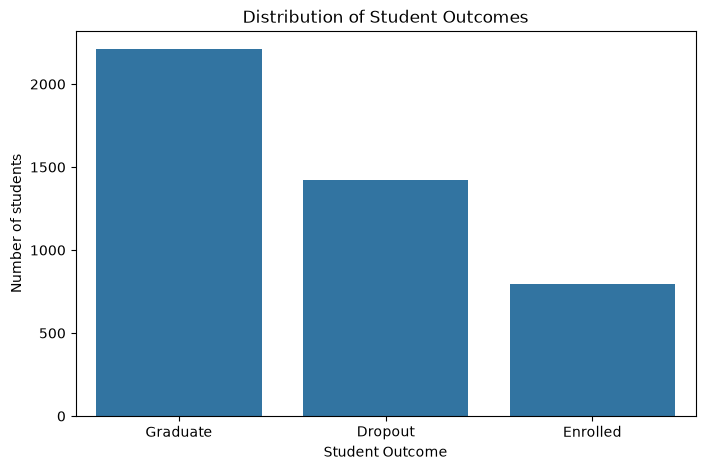

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Target",
    order=target_counts.index
)

plt.title("Distribution of Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of students")

plt.tight_layout
plt.show()

The target variable contains three classes with different proportions. Graduate is the majority class (49.94%), Dropout is the middle second majority (32.12%) and Enrolled is the minority class (17.95%). 


Fairer class proportions will be preserved by using 'Stratified train-test splitting' and 'Stratified cross-validation'.

# Data Types

In [11]:
#Display the dataset columns and their data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                             4424

# Unique Values

The number of unique values within each column (2 could suggest binary, 6 could suggest it is a category, a higher number likely represents a numerical measurement)


In [12]:
unique_values = df.nunique().sort_values(ascending=False)
print(unique_values)

Curricular units 1st sem (grade)                  805
Curricular units 2nd sem (grade)                  786
Age at enrollment                                  46
Father's occupation                                46
Curricular units 1st sem (evaluations)             35
Father's qualification                             34
Mother's occupation                                32
Curricular units 2nd sem (evaluations)             30
Mother's qualification                             29
Curricular units 1st sem (approved)                23
Curricular units 1st sem (enrolled)                23
Curricular units 2nd sem (enrolled)                22
Nacionality                                        21
Curricular units 1st sem (credited)                21
Curricular units 2nd sem (approved)                20
Curricular units 2nd sem (credited)                19
Application mode                                   18
Previous qualification                             17
Course                      

# Statistical Summaries (mean, standard deviation, min and max values, quartiles)

In [13]:
stat_sum = df.describe().T
print(stat_sum)

                                                 count       mean        std  \
Marital status                                  4424.0   1.178571   0.605747   
Application mode                                4424.0   6.886980   5.298964   
Application order                               4424.0   1.727848   1.313793   
Course                                          4424.0   9.899186   4.331792   
Daytime/evening attendance                      4424.0   0.890823   0.311897   
Previous qualification                          4424.0   2.531420   3.963707   
Nacionality                                     4424.0   1.254521   1.748447   
Mother's qualification                          4424.0  12.322107   9.026251   
Father's qualification                          4424.0  16.455244  11.044800   
Mother's occupation                             4424.0   7.317812   3.997828   
Father's occupation                             4424.0   7.819168   4.856692   
Displaced                               

Integer data types can be misleading. For example:

- COURSE (17 unique values), course 17 isn't mathematically greater than course 2 
- FATHERS OCCUPATION (46 unique values), these are occupation codes
- GENDER (2 unique values), so it's binary

# Define Feature Groups

In [14]:
#Nominal Categorical Features
categorical_features = [
    'Marital status',
    'Application mode',
    'Course',
    'Previous qualification',
    'Nacionality',
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

#Binary Features 
binary_features = [
    'Daytime/evening attendance',
    'Displaced',
    'Educational special needs',
    'Debtor',
    'Tuition fees up to date',
    'Gender',
    'Scholarship holder',
    'International'
]

#Ordinal Features
ordinal_features = [
    'Application order'
]

#Numerical Count Features
count_features = [
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (without evaluations)'
]

# Continuous numerical features
continuous_features = [
    'Age at enrollment',
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

# Validate Feature Group Classification

In [15]:
#Combine all of the feature groups
all_features = (
    categorical_features
    + binary_features
    + ordinal_features
    + count_features
    + continuous_features
)

#Check for any duplicated or missed classifications
missed_class = set(df.drop(columns="Target").columns) - set(all_features)
duplicate_class = len(all_features) != len(set(all_features))

#Print the results to check
print("Unclassified Features: ", missed_class)
print("Duplicated Classifications: ", duplicate_class)

Unclassified Features:  set()
Duplicated Classifications:  False


# Splitting the dataset (training and testing)

In [16]:
#X = dataset with target column dropped/removed
X = df.drop(columns=['Target'])

#Y = target column
y = df['Target']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#Dataset dimensions
print("Training Features: ", X_train.shape)
print("Testing Features: ", X_test.shape)

print("Training target: ", y_train.shape)
print("Testing Target: ", y_test.shape)

Training Features:  (3539, 34)
Testing Features:  (885, 34)
Training target:  (3539,)
Testing Target:  (885,)


# Stratification 

In [18]:
#Compare the distributions of the target class
split_distribution = pd.DataFrame({
    "Original": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
})
print(split_distribution.round(2))

          Original  Training  Testing
Target                               
Graduate     49.93     49.93    49.94
Dropout      32.12     32.13    32.09
Enrolled     17.95     17.94    17.97


# Combine Training Data Into One Data Frame

In [19]:
#Combining both the training features and targets (X_train, y_train)
training_eda = X_train.copy()
training_eda["Target"] = y_train

target_order = ["Graduate", "Dropout", "Enrolled"]

# Function for EDA (Barchart)

In [21]:
def plot_categorical_target(feature):

    #Contigency table
    counts = pd.crosstab(
        training_eda[feature],
        training_eda["Target"]
    )
    #Percentage with each feature category
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    #Keep target classes in the same order
    percentages = percentages.reindex(
        columns=target_order,
        fill_value=0
    )

    ax = percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )

    ax.set_title(f"{feature} vs Target")
    ax.set_xlabel(feature)
    ax.set_ylabel("Percentage of students")
    ax.set_ylim(0, 100)

    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Target")
    plt.tight_layout()
    plt.show

    return counts

# Function for EDA (count and percentages for features)

In [24]:
def print_categorical_target(feature):

    # Create contingency table
    counts = pd.crosstab(
        training_eda[feature],
        training_eda["Target"]
    )

    # Keep target classes in the same order
    counts = counts.reindex(
        columns=target_order,
        fill_value=0
    )

    # Calculate percentages within each feature category
    percentages = counts.div(
        counts.sum(axis=1),
        axis=0
    ) * 100

    # Print results
    print(f"\n{'='*50}")
    print(f"{feature} vs Target")
    print(f"{'='*50}")

    print("\nStudent counts:")
    print(counts.to_string())

    print("\nPercentage breakdown (%):")
    print(percentages.round(2).to_string())

    return counts, percentages

# Function for EDA (Boxplots for Numerical Fetures)

In [41]:
import math

def plot_numeric_features(features, columns=2):

    rows = math.ceil(len(features) / columns)

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(14, rows * 4)
    )

    axes = np.array(axes).reshape(-1)

    for ax, feature in zip(axes, features):

        sns.boxplot(
            data=training_eda,
            x='Target',
            y=feature,
            order=target_order,
            ax=ax,
            showfliers=False
        )

        ax.set_title(f'{feature} vs Target')
        ax.set_xlabel('Target')
        ax.set_ylabel(feature)

    # Remove unused subplot spaces
    for ax in axes[len(features):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

    # -------------------------
    # Numerical output
    # -------------------------

    for feature in features:

        # Calculate descriptive statistics for each target class
        summary = training_eda.groupby('Target')[feature].describe()

        # Keep target classes in the correct order
        summary = summary.reindex(target_order)

        # Rename columns for clarity
        summary = summary.rename(columns={
            '25%': 'Q1',
            '50%': 'Median',
            '75%': 'Q3'
        })

        # Round numerical values
        summary = summary.round(2)

        print(f'\n{feature} vs Target')
        print('=' * 70)
        print(summary.to_string())

# Categorical features in relation to target class

In [25]:
for feature in categorical_features:
    print_categorical_target(feature)


Marital status vs Target

Student counts:
Target          Graduate  Dropout  Enrolled
Marital status                             
1                   1615      948       581
2                    114      144        38
3                      1        1         1
4                     28       33        12
5                      9        8         2
6                      0        3         1

Percentage breakdown (%):
Target          Graduate  Dropout  Enrolled
Marital status                             
1                  51.37    30.15     18.48
2                  38.51    48.65     12.84
3                  33.33    33.33     33.33
4                  38.36    45.21     16.44
5                  47.37    42.11     10.53
6                   0.00    75.00     25.00

Application mode vs Target

Student counts:
Target            Graduate  Dropout  Enrolled
Application mode                             
1                      865      267       232
2                        1        2        

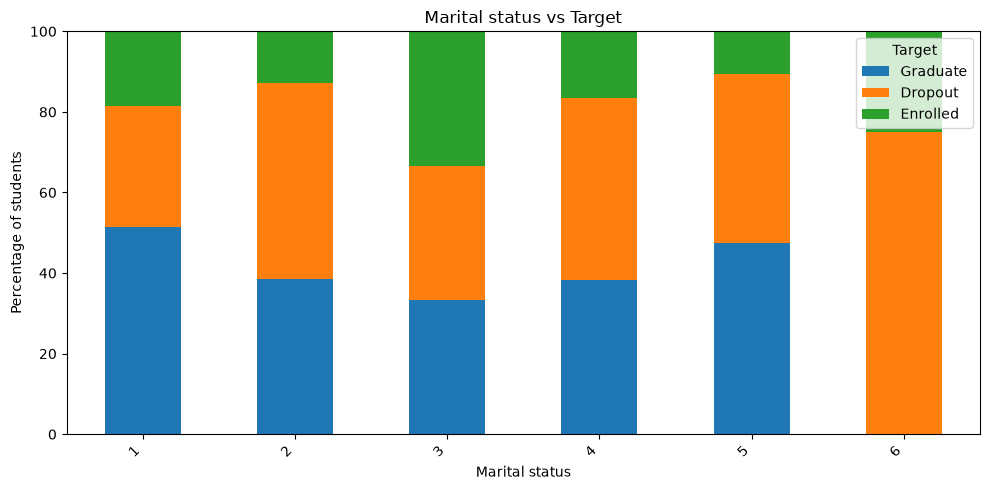

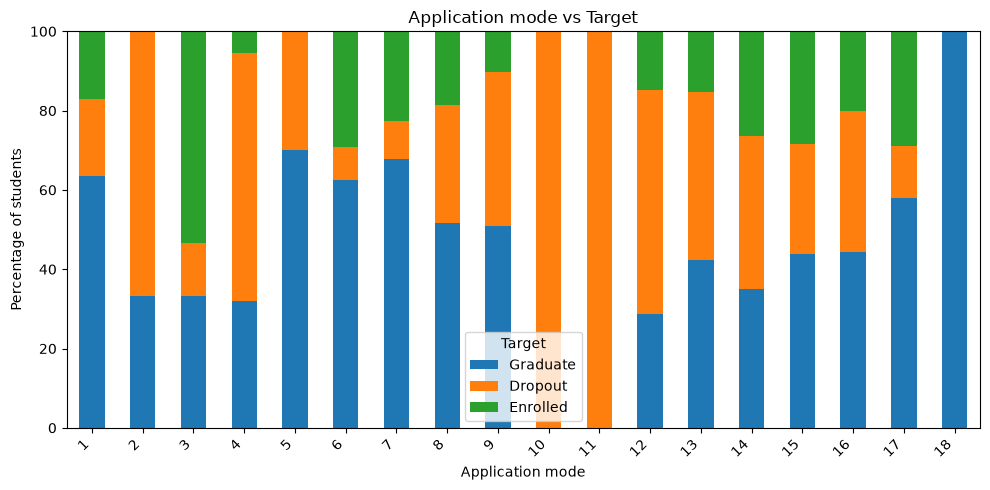

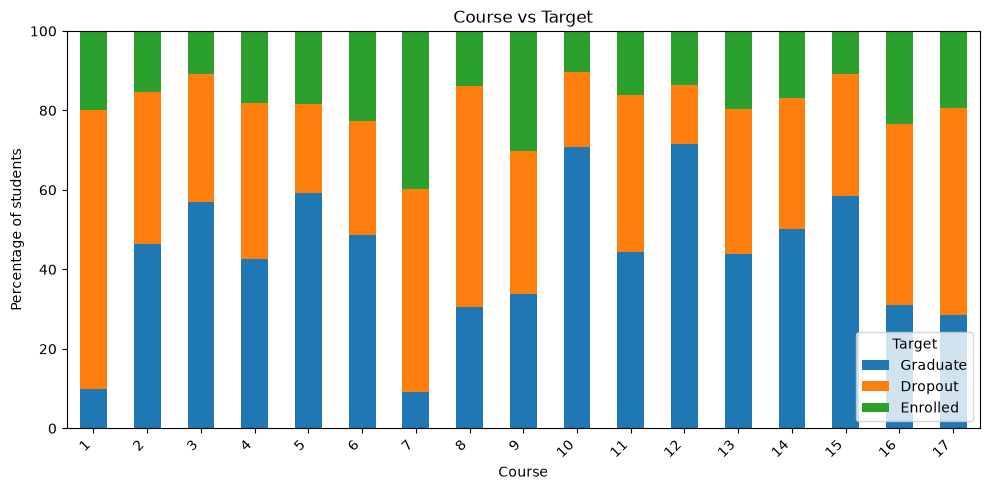

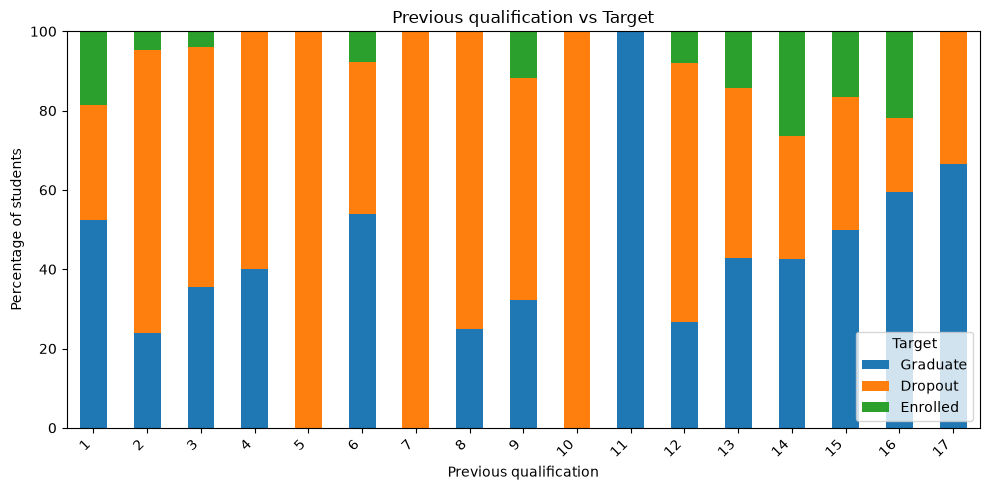

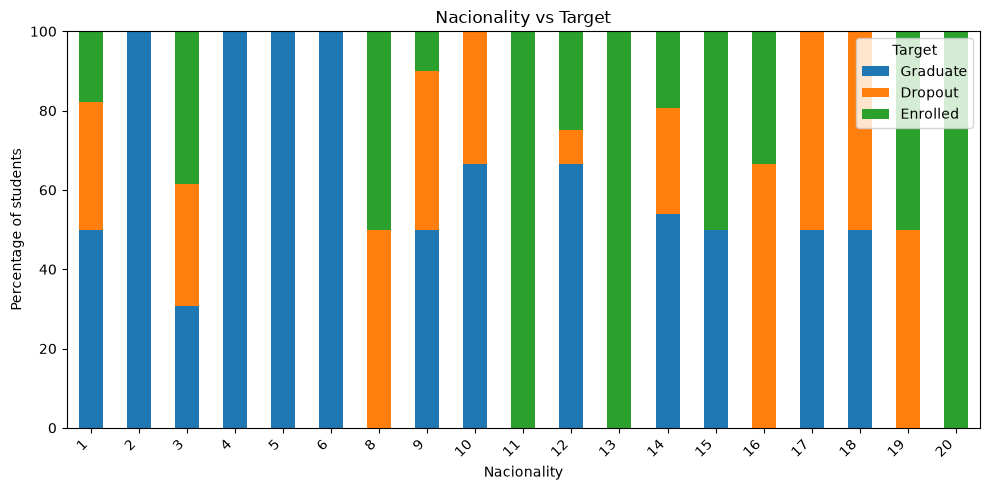

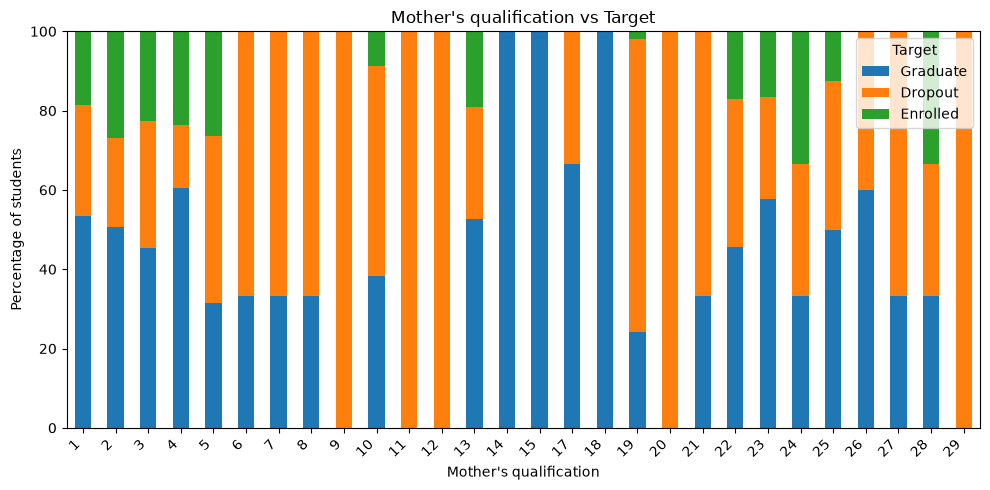

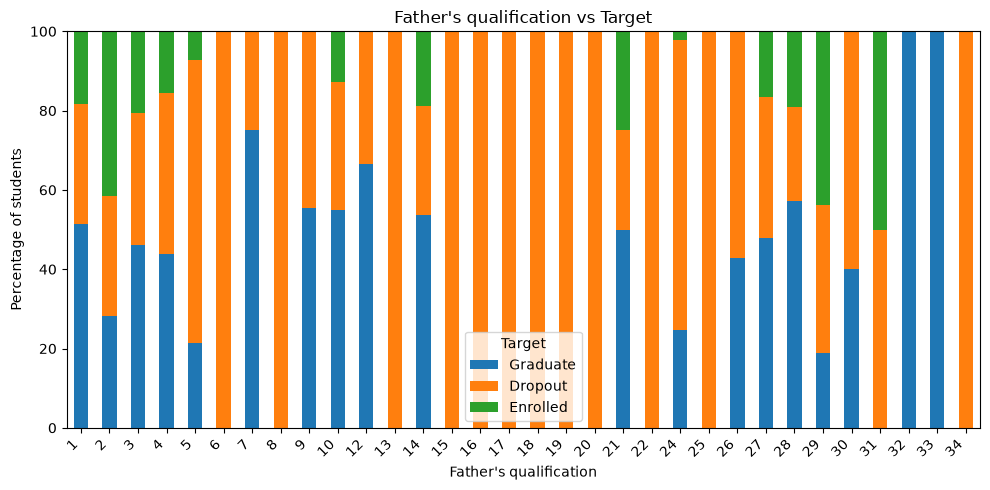

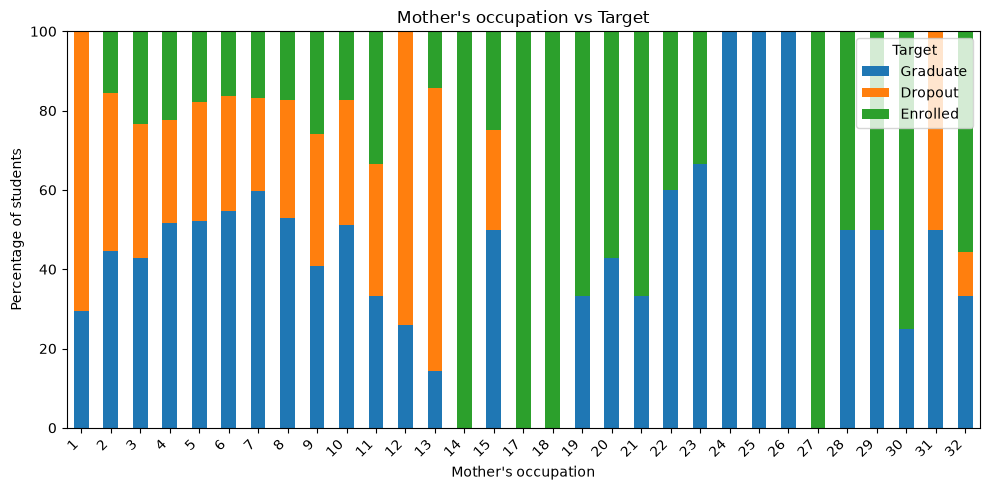

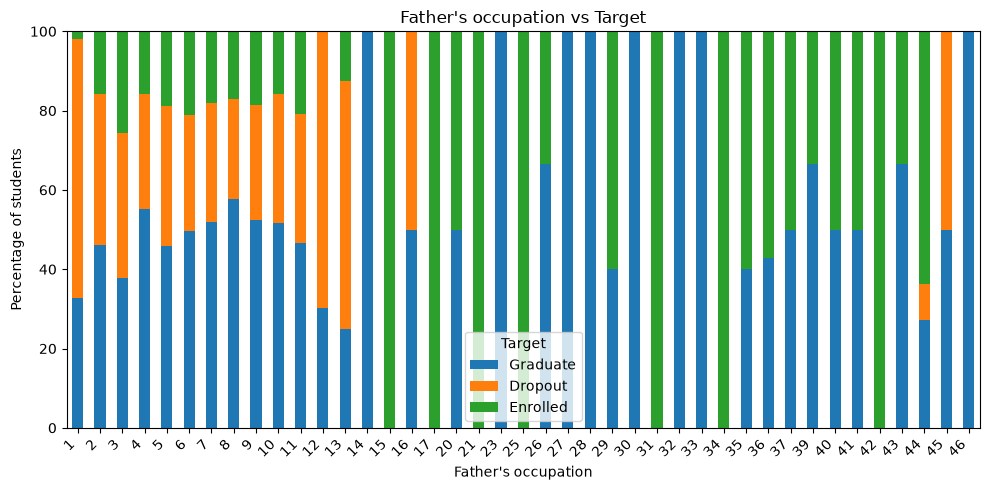

In [22]:
for feature in categorical_features:
    plot_categorical_target(feature)

# Binary Features in Relation to Target Class

In [28]:
for feature in binary_features:
    print_categorical_target(feature)


Daytime/evening attendance vs Target

Student counts:
Target                      Graduate  Dropout  Enrolled
Daytime/evening attendance                             
0                                156      166        60
1                               1611      971       575

Percentage breakdown (%):
Target                      Graduate  Dropout  Enrolled
Daytime/evening attendance                             
0                              40.84    43.46     15.71
1                              51.03    30.76     18.21

Displaced vs Target

Student counts:
Target     Graduate  Dropout  Enrolled
Displaced                             
0               704      603       290
1              1063      534       345

Percentage breakdown (%):
Target     Graduate  Dropout  Enrolled
Displaced                             
0             44.08    37.76     18.16
1             54.74    27.50     17.77

Educational special needs vs Target

Student counts:
Target                     Graduate  Dr

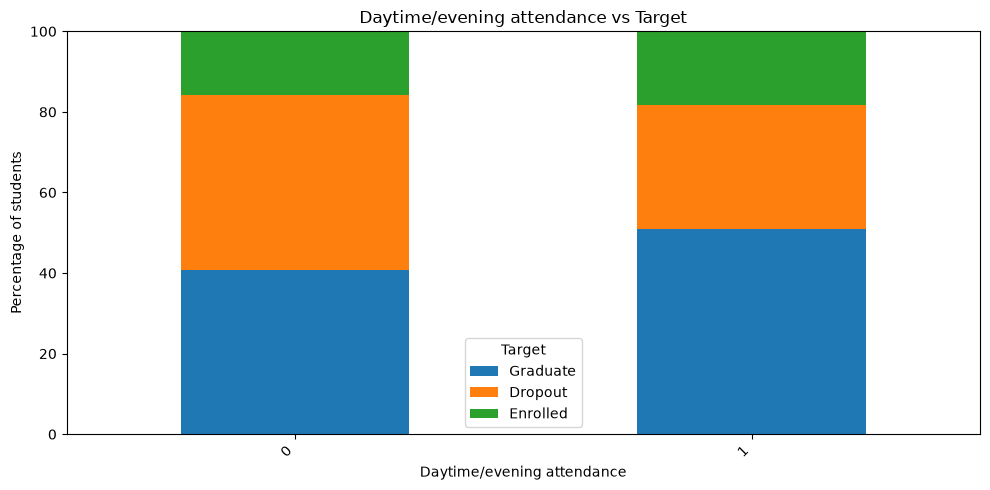

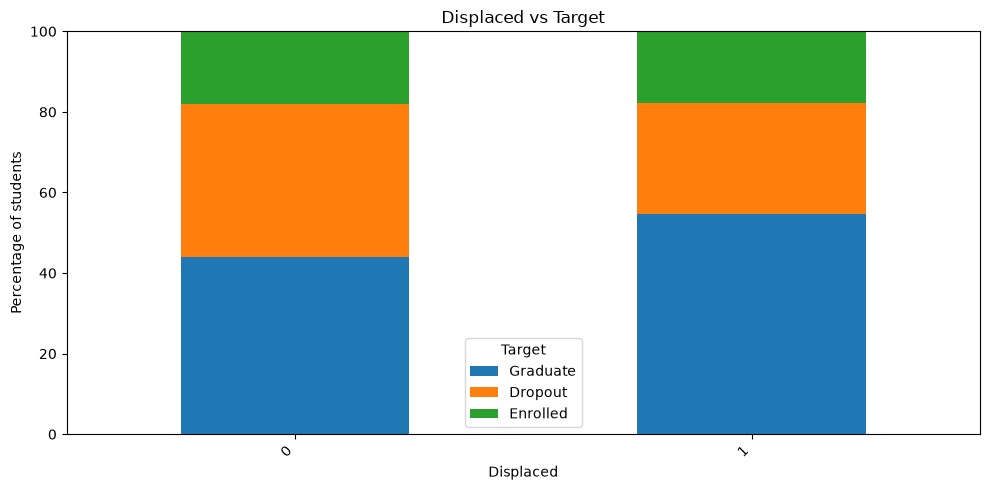

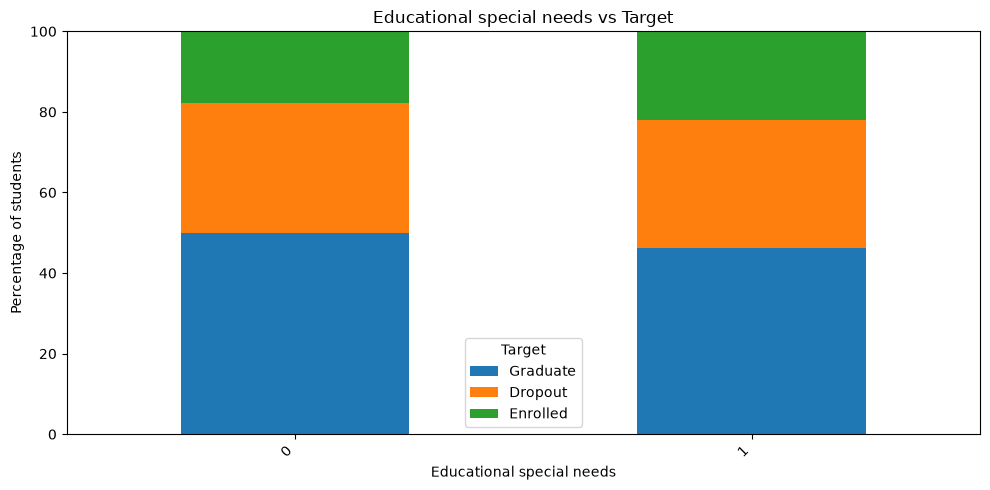

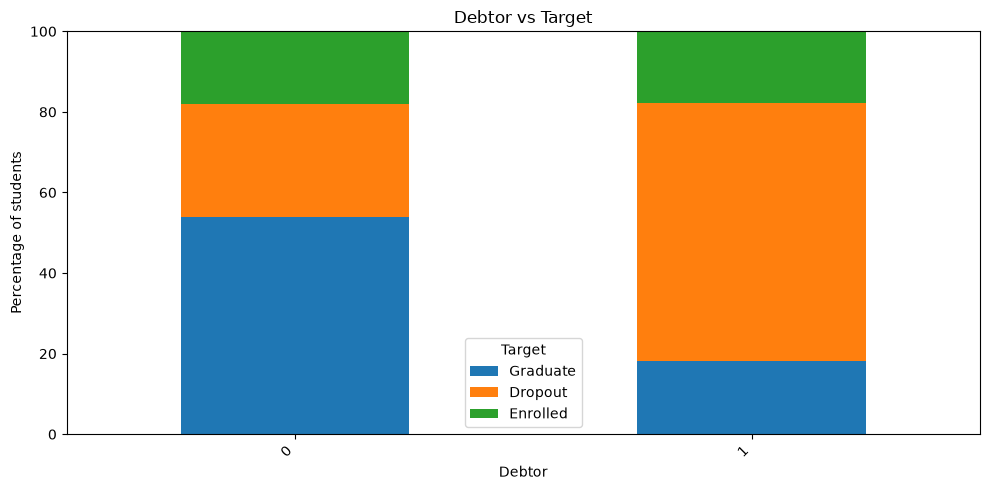

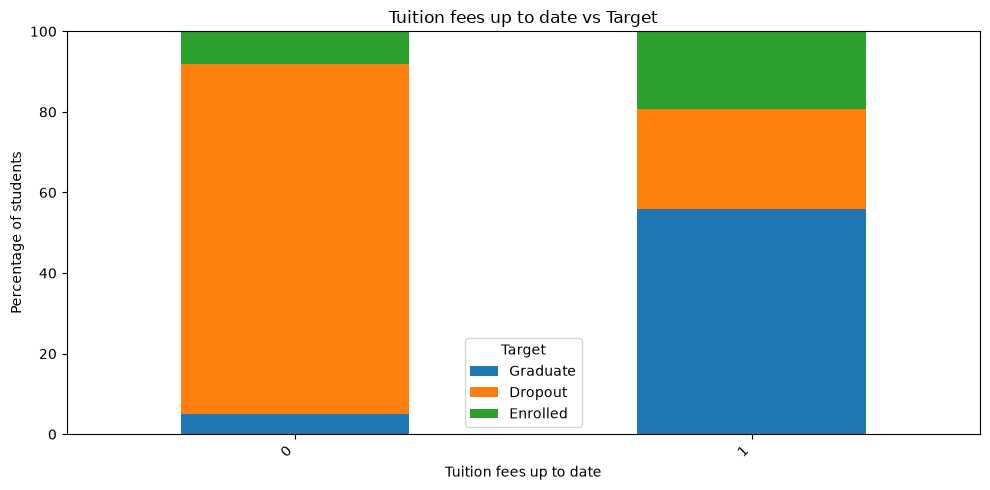

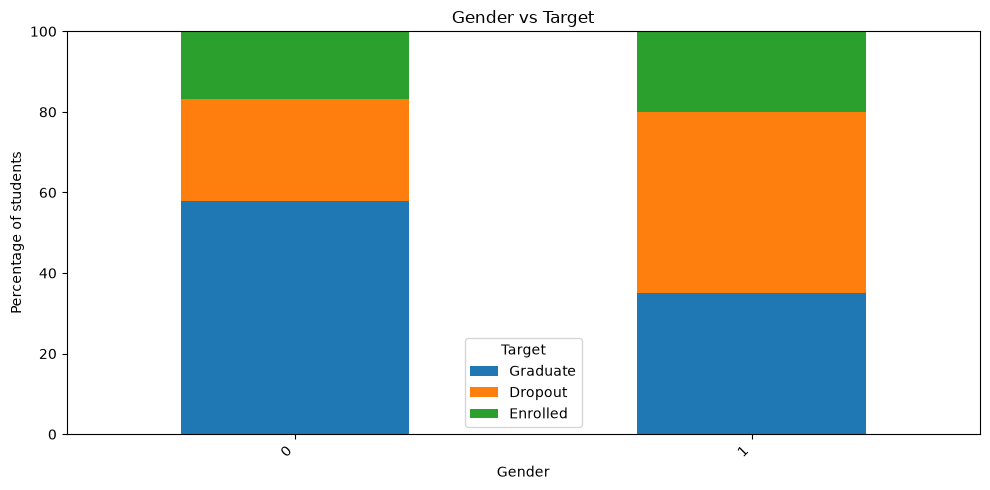

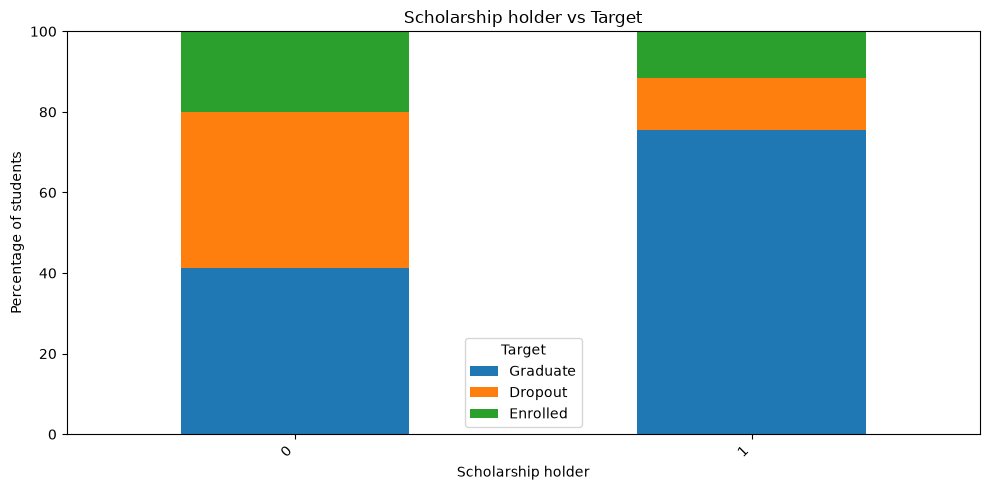

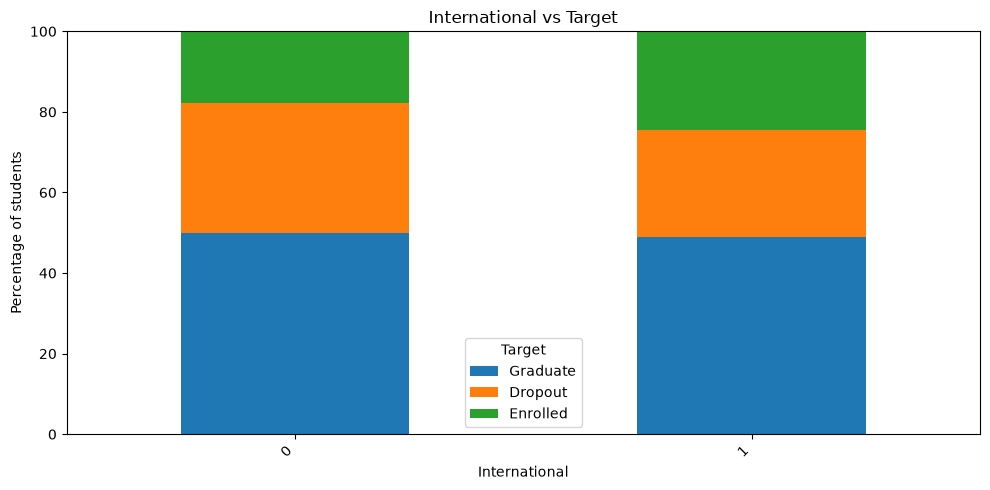

In [27]:
for feature in binary_features:
    plot_categorical_target(feature)

# Ordinal Features in Relation to Target Class

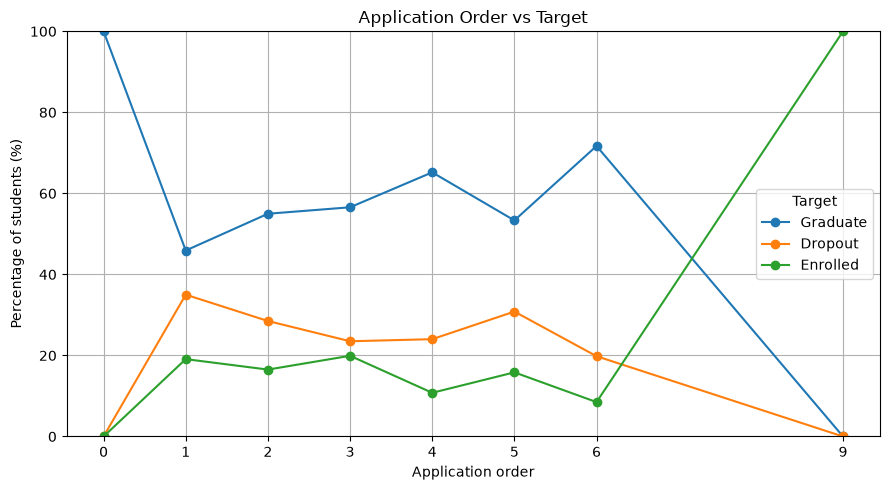


Application order vs Target
                   Total students  Graduate (n)  Graduate (%)  Dropout (n)  Dropout (%)  Enrolled (n)  Enrolled (%)
Application order                                                                                                  
0                               1             1         100.0            0          0.0             0           0.0
1                            2414          1108          45.9          845         35.0           461          19.1
2                             442           243          55.0          126         28.5            73          16.5
3                             251           142          56.6           59         23.5            50          19.9
4                             204           133          65.2           49         24.0            22          10.8
5                             120            64          53.3           37         30.8            19          15.8
6                             106          

In [40]:
feature = 'Application order'

#Count students by application order and target
counts = pd.crosstab(
    training_eda[feature],
    training_eda['Target']
)

#Calculate percentages within each application order
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

#Keep target classes in the correct order
percentages = percentages.reindex(
    columns=target_order,
    fill_value=0
)

percentages.plot(
    kind='line',
    marker='o',
    figsize=(9, 5)
)

plt.title('Application Order vs Target')
plt.xlabel('Application order')
plt.ylabel('Percentage of students (%)')
plt.xticks(percentages.index)
plt.ylim(0, 100)
plt.legend(title='Target')
plt.grid(True)
plt.tight_layout()
plt.show()

# Create a table containing counts and percentages
output = pd.DataFrame(index=counts.index)

output['Total students'] = counts.sum(axis=1)

for target in target_order:
    output[f'{target} (n)'] = counts[target]
    output[f'{target} (%)'] = percentages[target].round(1)

print(f'\n{feature} vs Target')
print('=' * 60)
print(output.to_string())

# Numerical Features in Relation to Target Class

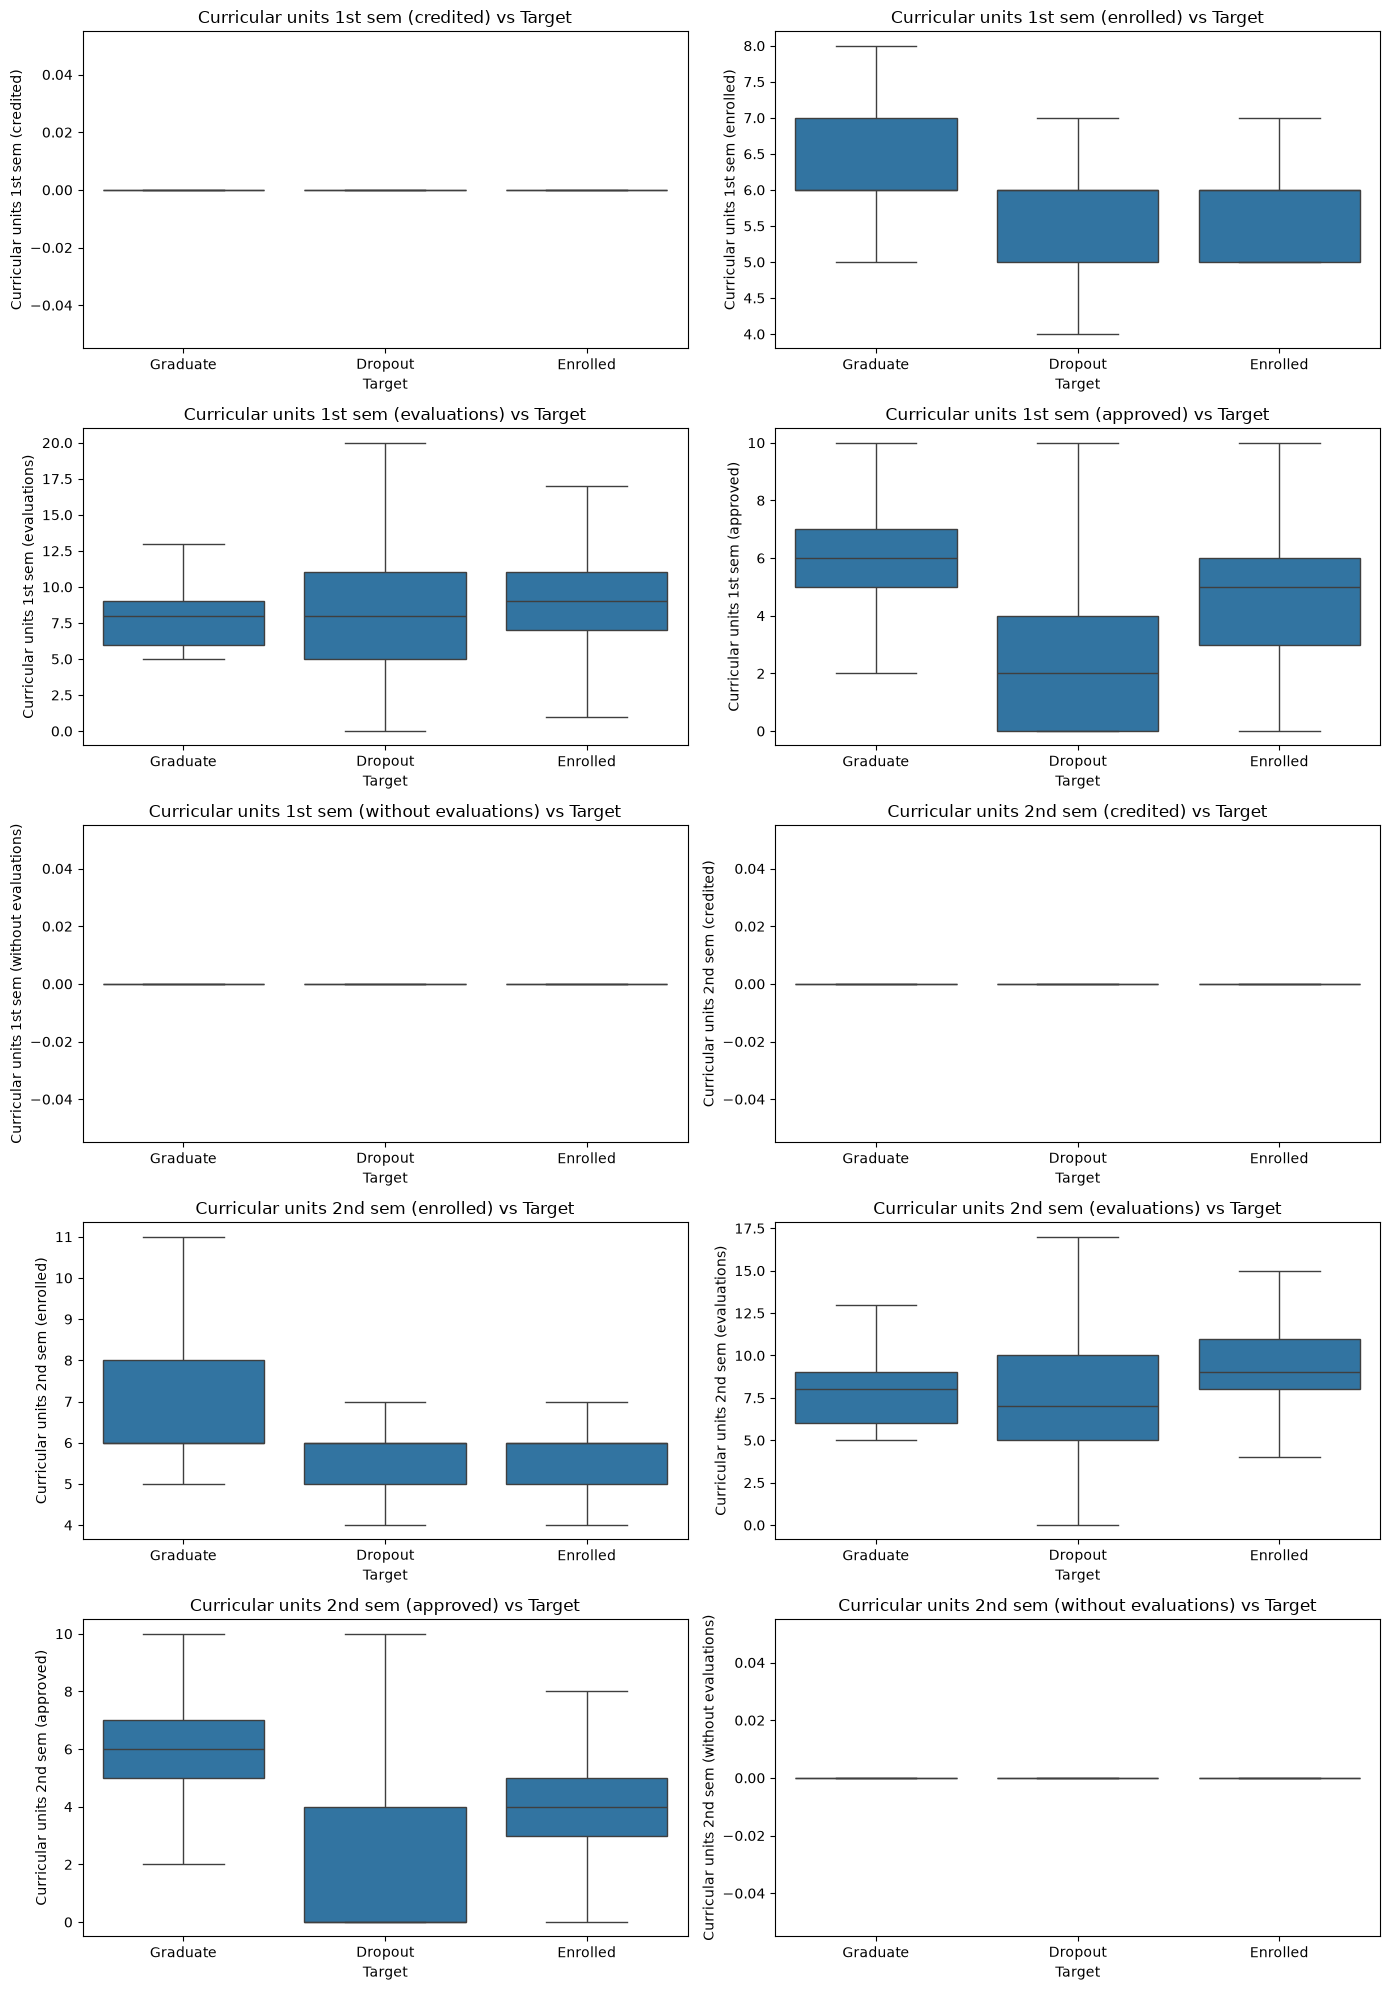


Curricular units 1st sem (credited) vs Target
           count  mean   std  min   Q1  Median   Q3   max
Target                                                   
Graduate  1767.0  0.82  2.65  0.0  0.0     0.0  0.0  20.0
Dropout   1137.0  0.65  2.19  0.0  0.0     0.0  0.0  18.0
Enrolled   635.0  0.57  1.83  0.0  0.0     0.0  0.0  14.0

Curricular units 1st sem (enrolled) vs Target
           count  mean   std  min   Q1  Median   Q3   max
Target                                                   
Graduate  1767.0  6.63  2.66  0.0  6.0     6.0  7.0  26.0
Dropout   1137.0  5.83  2.39  0.0  5.0     6.0  6.0  21.0
Enrolled   635.0  6.02  2.02  0.0  5.0     6.0  6.0  17.0

Curricular units 1st sem (evaluations) vs Target
           count  mean   std  min   Q1  Median    Q3   max
Target                                                    
Graduate  1767.0  8.22  3.74  0.0  6.0     8.0   9.0  45.0
Dropout   1137.0  7.75  4.99  0.0  5.0     8.0  11.0  31.0
Enrolled   635.0  9.45  3.50  0.0  7.0  

In [42]:
plot_numeric_features(count_features)

# Continuous Numerical Features in Relation to Target Class

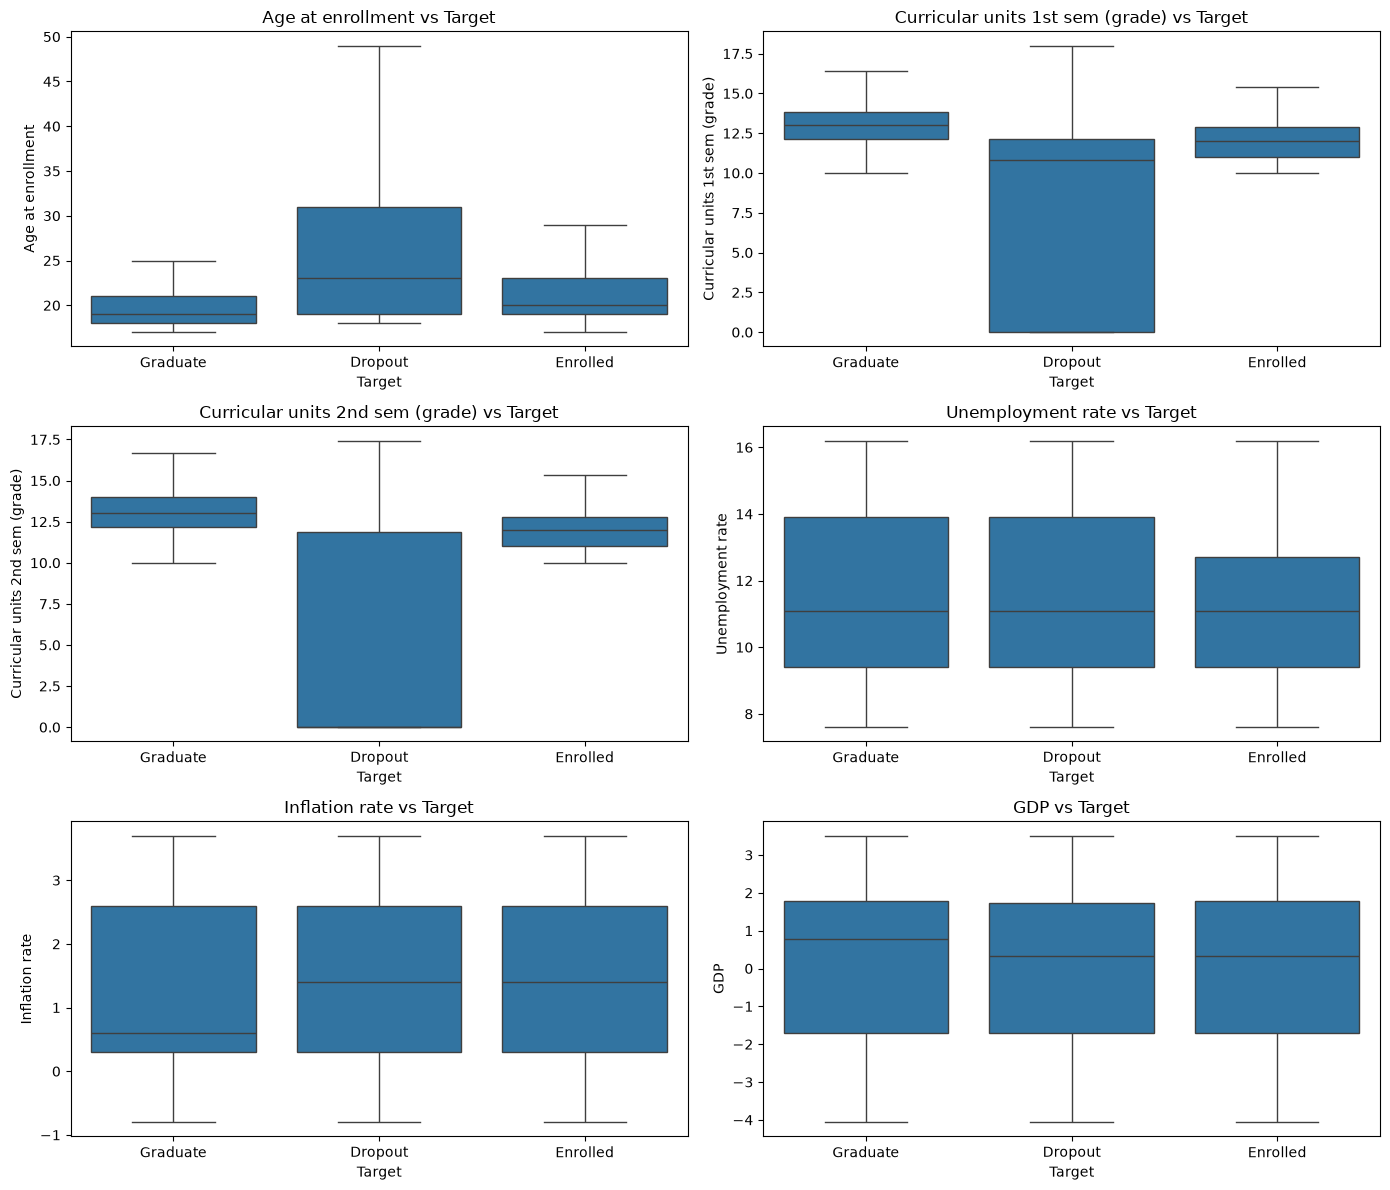


Age at enrollment vs Target
           count   mean   std   min    Q1  Median    Q3   max
Target                                                       
Graduate  1767.0  21.74  6.73  17.0  18.0    19.0  21.0  62.0
Dropout   1137.0  26.07  8.67  18.0  19.0    23.0  31.0  70.0
Enrolled   635.0  22.40  6.37  17.0  19.0    20.0  23.0  54.0

Curricular units 1st sem (grade) vs Target
           count   mean   std  min     Q1  Median     Q3    max
Target                                                         
Graduate  1767.0  12.63  2.76  0.0  12.14   13.00  13.86  18.88
Dropout   1137.0   7.21  6.03  0.0   0.00   10.83  12.17  18.00
Enrolled   635.0  11.14  3.68  0.0  11.00   12.00  12.86  17.00

Curricular units 2nd sem (grade) vs Target
           count   mean   std  min     Q1  Median     Q3    max
Target                                                         
Graduate  1767.0  12.67  2.75  0.0  12.17    13.0  14.00  18.57
Dropout   1137.0   5.84  6.12  0.0   0.00     0.0  11.88  17.

In [43]:
plot_numeric_features(continuous_features)

# Spearman Correlation Heat Map (numerical feature to feature relationships)

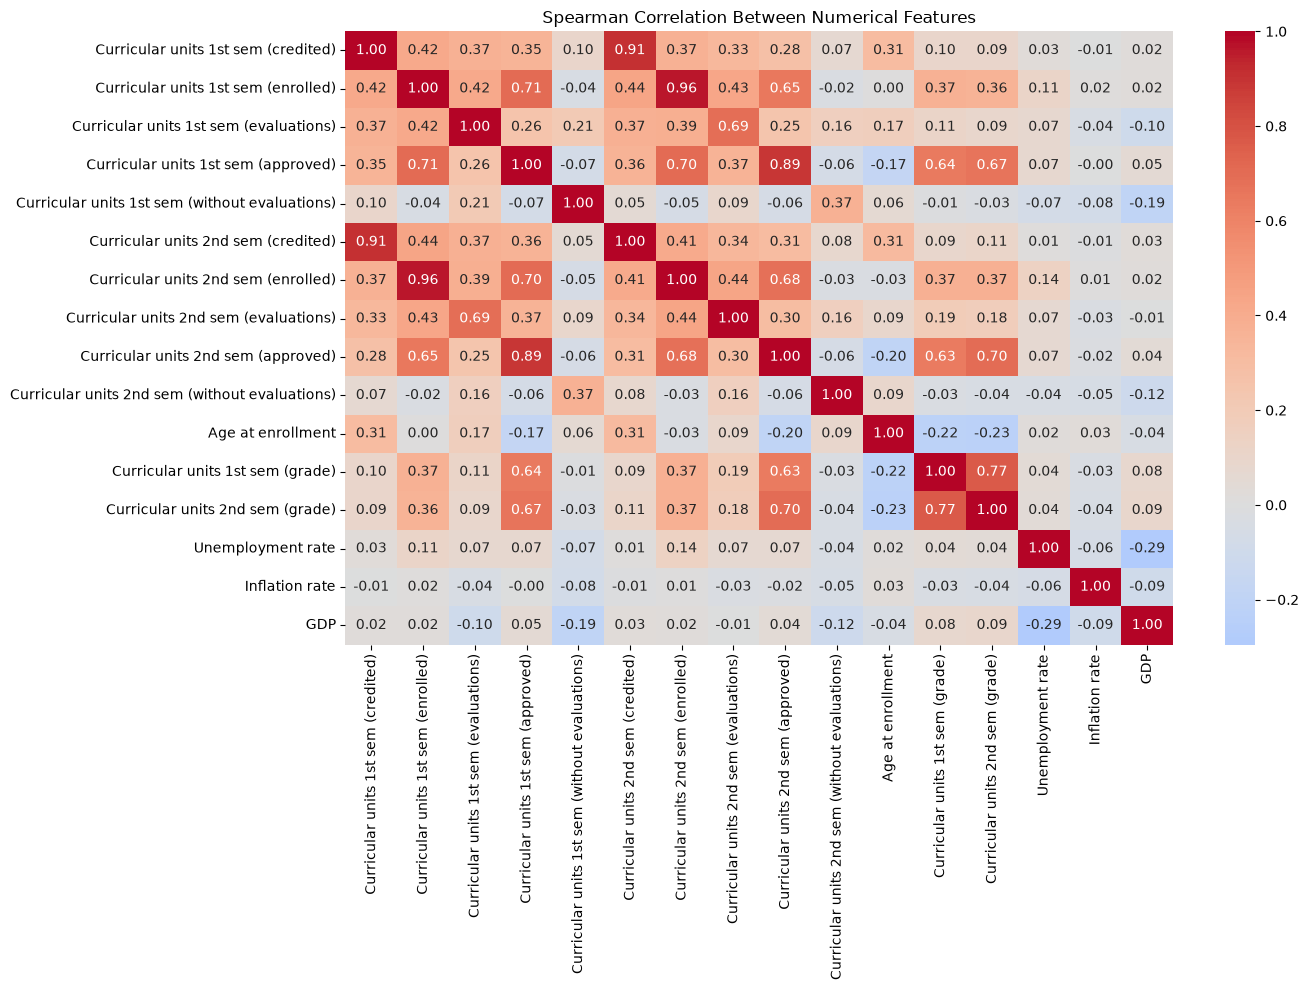

In [45]:
#Only using numerical features (categorical wouldn't work here)
numerical_features = count_features + continuous_features

#Spearman correlation
correlation_matrix = training_eda[numerical_features].corr(
    method='spearman'
)

#Heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Spearman Correlation Between Numerical Features')
plt.tight_layout()
plt.show()
